# بوصلة الأثر (Athar Compass)
## كفاءة الأثر في مبادرات القطاع الثالث
**هاكثون تحليل بيانات القطاع الثالث · الفكرة: تحسين أداء البرامج والمبادرات (الأكثر تأثيرًا مقابل التمويل)**

**سؤال القرار:** هل يرتفع الأثر بنفس نسبة ارتفاع التمويل؟ وهل تختلف كلفة الشخص المتأثر باختلاف حجم المبادرة ونوعها؟

**القرار المطلوب:** هل نوجّه التمويل المقبل نحو مبادرات أصغر حجمًا، أم نواصل تمويل المبادرات الكبيرة؟

**المصدر:** مجموعة Interdependence NGOs by Funding, Reach (Kaggle) · كل صف منظمة، ولا توجد بيانات أفراد.

**ترتيب التشغيل:** شغّل الخلايا من الأعلى إلى الأسفل (Restart session and run all). يُنتج الدفتر: `data_clean/` و`outputs/figures/` و`report/executive_summary.pdf`.

In [1]:
%pip -q install arabic-reshaper python-bidi kagglehub scipy
import json, textwrap
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy import stats
import arabic_reshaper
from bidi.algorithm import get_display

def ar(s): return get_display(arabic_reshaper.reshape(str(s)))
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
for d in ["data_clean", "outputs/figures", "report"]:
    Path(d).mkdir(parents=True, exist_ok=True)
SEED = 42
NAVY, TEAL, CORAL, YELLOW = "#355483", "#1A9496", "#EC6157", "#F5B82E"

Note: you may need to restart the kernel to use updated packages.


## 1) تحميل البيانات

In [2]:
CANDIDATES = [Path("data_raw/interdependence-orgs.csv"), Path("interdependence-orgs.csv")]
src = next((p for p in CANDIDATES if p.exists()), None)
if src is None:                                   # تنزيل تلقائي من Kaggle
    import kagglehub
    src = Path(kagglehub.dataset_download("utkarshx27/interdependence-ngos-by-funding-reach")) / "interdependence-orgs.csv"
raw = pd.read_csv(src)                            # النسخة الأصلية: لا تُعدَّل أبدًا
print("المصدر:", src.name, "| الشكل:", raw.shape)

المصدر: interdependence-orgs.csv | الشكل: (155, 24)


## 2) فحص الجودة قبل التنظيف (قراءة فقط)

In [3]:
miss = (raw.isna().mean() * 100).round(1).sort_values(ascending=False)
print("أعلى الأعمدة فراغًا (%):"); print(miss[miss > 0].head(10).to_string())
print("\nصفوف مكررة بالكامل:", int(raw.duplicated().sum()))
key = raw["label"].astype(str).str.strip().str.lower()
print("أسماء منظمات مكررة:", int(key.duplicated().sum()))
print("قيمة ? في أعمدة التمويل:", int(sum((raw[c].astype(str).str.strip() == "?").sum() for c in raw.columns if c.startswith("Funding ("))))
print("أثر مقدّر = 1,000,000 بالضبط:", int((raw["Est. People Impacted"] == 1_000_000).sum()))
print("تمويل ثلاث سنوات = صفر:", int((raw["Three-Year-Funding"] == 0).sum()))

أعلى الأعمدة فراغًا (%):
Unnamed: 23            99.4
Cultural Isolation     92.3
Polarization           88.4
Holistic Knowledge     85.2
Behavior               80.0
Mindset                80.0
Interdependence        80.0
Scale                  76.8
Funding (2015)         44.5
Number of Employees    43.9

صفوف مكررة بالكامل: 0
أسماء منظمات مكررة: 2
قيمة ? في أعمدة التمويل: 101
أثر مقدّر = 1,000,000 بالضبط: 7
تمويل ثلاث سنوات = صفر: 58


## 3) التنظيف مع سجل التغييرات
قواعد التنظيف (كل تغيير يُسجَّل في `data_clean/cleaning_log.csv`):
1. حذف عمودين: `Unnamed: 23` (فارغ تقريبًا) و`Image` (روابط صور).
2. تحويل أعمدة التمويل السنوية إلى أرقام (`?` تصبح فارغة).
3. التمويل الصفري أو أقل من 1,000 دولار لثلاث سنوات → فارغ (افتراض: غير مبلَّغ عنه أو خطأ ترميز).
4. عدد موظفين أكبر من 10,000 → فارغ (خطأ إدخال محتمل).
5. **لا نحذف أي صف.** نعلّمه في `qc_flags`: الأسماء المكررة بقيم متضاربة، والأثر المقدّر 1,000,000 بالضبط، ثم نستبعد المعلَّم من التحليل.

In [4]:
CHANGELOG = []
def log(step, col, org, old, new, reason):
    CHANGELOG.append(dict(step=step, column=col, organization=org, old=old, new=new, reason=reason))

def clean_data(raw):
    df = raw.copy()
    df.columns = df.columns.str.strip()
    for c in ["label", "type", "Tags", "Description"]:
        df[c] = df[c].astype("string").str.strip()
    df["Tags"] = df["Tags"].str.replace(r"\s*\|\s*", " | ", regex=True)

    drop = [c for c in ["Unnamed: 23", "Image"] if c in df.columns]
    for c in drop: log("drop_column", c, "", "", "", "عمود فارغ تقريبًا أو روابط صور")
    df = df.drop(columns=drop)

    for c in [c for c in df.columns if c.startswith("Funding (")]:
        s = df[c].astype("string").str.replace(r"[\$,\s]", "", regex=True)
        conv = pd.to_numeric(s.replace({"?": pd.NA, "": pd.NA}), errors="coerce")
        for i in df.index[s.notna() & conv.isna()]:
            log("to_numeric", c, df.label[i], df[c][i], "", "قيمة غير رقمية")
        df[c] = conv

    f = df["Three-Year-Funding"]
    for mask, why in [(f <= 0, "صفر: يُعدّ غير مبلَّغ عنه (افتراض)"),
                      ((f > 0) & (f < 1000), "أقل من 1,000 دولار لثلاث سنوات: خطأ ترميز محتمل")]:
        for i in df.index[mask]: log("to_nan", "Three-Year-Funding", df.label[i], f[i], "", why)
        df.loc[mask, "Three-Year-Funding"] = np.nan
    e = df["Number of Employees"]
    for i in df.index[e > 10000]: log("to_nan", "Number of Employees", df.label[i], e[i], "", "عدد موظفين غير منطقي")
    df.loc[e > 10000, "Number of Employees"] = np.nan

    df["qc_flags"] = ""
    def flag(mask, tag, why):
        for i in df.index[mask]: log("flag", "qc_flags", df.label[i], "", tag, why)
        df.loc[mask, "qc_flags"] = df.loc[mask, "qc_flags"] + tag + ";"
    flag(df.label.str.lower().duplicated(keep=False), "dup_name", "اسم مكرر بقيم متضاربة: يُستبعد من التحليل")
    flag(df["Est. People Impacted"] == 1_000_000, "impact_1e6", "أثر مقدّر 1,000,000 بالضبط: قيمة سقف مشبوهة")
    df["in_analysis"] = (df.qc_flags == "") & df["Three-Year-Funding"].notna() & (df["Est. People Impacted"] > 0)
    return df

df = clean_data(raw)
df.to_csv("data_clean/ngo_clean.csv", index=False, encoding="utf-8-sig")
changelog = pd.DataFrame(CHANGELOG)
changelog.to_csv("data_clean/cleaning_log.csv", index=False, encoding="utf-8-sig")
print("صفوف:", len(df), "| تغييرات مسجّلة:", len(changelog))
display(changelog.groupby(["step", "reason"]).size().rename("عدد").reset_index())

صفوف: 155 | تغييرات مسجّلة: 174


,step,reason,عدد
0,drop_column,عمود فارغ تقريبًا أو روابط صور,2
1,flag,"أثر مقدّر 1,000,000 بالضبط: قيمة سقف مشبوهة",7
2,flag,اسم مكرر بقيم متضاربة: يُستبعد من التحليل,4
3,to_nan,"أقل من 1,000 دولار لثلاث سنوات: خطأ ترميز محتمل",1
4,to_nan,صفر: يُعدّ غير مبلَّغ عنه (افتراض),58
5,to_nan,عدد موظفين غير منطقي,1
6,to_numeric,قيمة غير رقمية,101


## 4) من 155 منظمة إلى عيّنة التحليل (شفافية الاستبعاد)

In [5]:
m = pd.Series(True, index=df.index)
rows = [("كل المنظمات", int(m.sum()))]
for name, cond in [("بدون اسم مكرر متضارب", ~df.qc_flags.str.contains("dup_name")),
                   ("بدون أثر مقدّر مشبوه (1,000,000)", ~df.qc_flags.str.contains("impact_1e6")),
                   ("تمويل ثلاث سنوات صالح", df["Three-Year-Funding"].notna()),
                   ("أثر مقدّر موجب", df["Est. People Impacted"] > 0)]:
    m &= cond; rows.append((name, int(m.sum())))
attrition = pd.DataFrame(rows, columns=["الخطوة", "المنظمات المتبقية"])
display(attrition)
A = df[df.in_analysis].copy()
A["cost_per_person"] = A["Three-Year-Funding"] / A["Est. People Impacted"]      # مؤشر الكلفة (دولار لكل شخص)
A["size"] = pd.qcut(A["Three-Year-Funding"], 3, labels=["صغير", "متوسط", "كبير"])  # حجم التمويل بالثلثين
N_A, N_ALL = len(A), len(df)
print("عيّنة التحليل:", N_A, "من", N_ALL)

,الخطوة,المنظمات المتبقية
0,كل المنظمات,155
1,بدون اسم مكرر متضارب,151
2,"بدون أثر مقدّر مشبوه (1,000,000)",145
3,تمويل ثلاث سنوات صالح,54
4,أثر مقدّر موجب,54


عيّنة التحليل: 54 من 155


## 5) التحليل (أ): هل تتغير كلفة الأثر مع حجم التمويل؟

,n,median_funding,median_people,median_cost_per_person
size,,,,
صغير,18,675000.0,8224.5,34.2
متوسط,18,4678234.5,30000.0,185.5
كبير,18,23357726.0,70000.0,514.3


Kruskal-Wallis (الكلفة حسب الحجم): H=9.77, p=0.0076
الكبيرة مقابل البقية (Mann-Whitney أحادي الاتجاه): p=0.0052
مرونة الأثر للتمويل (انحدار لوغاريتمي): 0.30  [95%: -0.05 ، 0.66]
ارتباط سبيرمان بين التمويل والأثر: rho=0.26, p=0.056


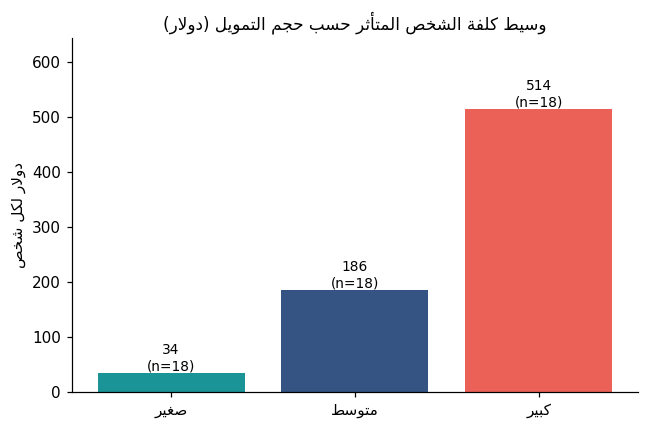

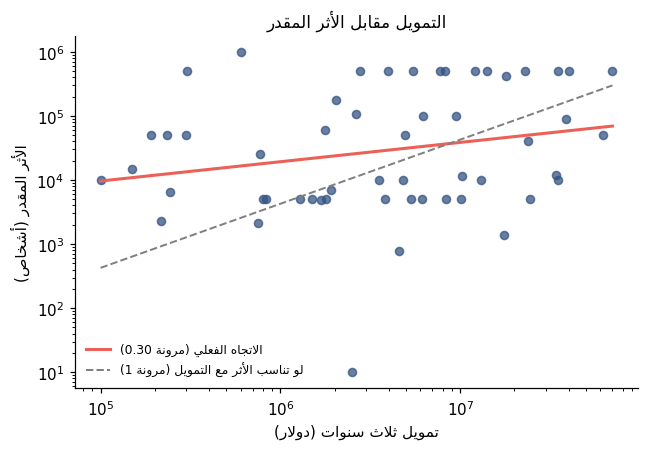

In [6]:
SIZES = ["صغير", "متوسط", "كبير"]
tab = (A.groupby("size", observed=True)
         .agg(n=("cost_per_person", "size"), median_funding=("Three-Year-Funding", "median"),
              median_people=("Est. People Impacted", "median"), median_cost_per_person=("cost_per_person", "median"))
         .round(1))
display(tab)
kw = stats.kruskal(*[A.loc[A["size"] == s, "cost_per_person"] for s in SIZES])
mw = stats.mannwhitneyu(A.loc[A["size"] == "كبير", "cost_per_person"], A.loc[A["size"] != "كبير", "cost_per_person"], alternative="greater")
lr = stats.linregress(np.log10(A["Three-Year-Funding"]), np.log10(A["Est. People Impacted"]))
slope = lr.slope; lo, hi = slope - 1.96 * lr.stderr, slope + 1.96 * lr.stderr
rho, p_rho = stats.spearmanr(A["Three-Year-Funding"], A["Est. People Impacted"])
print(f"Kruskal-Wallis (الكلفة حسب الحجم): H={kw.statistic:.2f}, p={kw.pvalue:.4f}")
print(f"الكبيرة مقابل البقية (Mann-Whitney أحادي الاتجاه): p={mw.pvalue:.4f}")
print(f"مرونة الأثر للتمويل (انحدار لوغاريتمي): {slope:.2f}  [95%: {lo:.2f} ، {hi:.2f}]")
print(f"ارتباط سبيرمان بين التمويل والأثر: rho={rho:.2f}, p={p_rho:.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
vals = [tab.loc[s, "median_cost_per_person"] for s in SIZES]
bars = ax.bar([ar(s) for s in SIZES], vals, color=[TEAL, NAVY, CORAL])
for b, v, s in zip(bars, vals, SIZES):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,.0f}\n(n={tab.loc[s, 'n']})", ha="center", va="bottom", fontsize=9)
ax.set_title(ar("وسيط كلفة الشخص المتأثر حسب حجم التمويل (دولار)"), fontsize=11)
ax.set_ylabel(ar("دولار لكل شخص")); ax.set_ylim(0, max(vals) * 1.25)
fig.tight_layout(); fig.savefig("outputs/figures/fig1_cost_by_size.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.scatter(A["Three-Year-Funding"], A["Est. People Impacted"], s=28, color=NAVY, alpha=.75)
xs = np.logspace(np.log10(A["Three-Year-Funding"].min()), np.log10(A["Three-Year-Funding"].max()), 50)
ax.plot(xs, 10 ** (lr.intercept + slope * np.log10(xs)), color=CORAL, lw=2, label=ar(f"الاتجاه الفعلي (مرونة {slope:.2f})"))
x0, y0 = A["Three-Year-Funding"].median(), A["Est. People Impacted"].median()
ax.plot(xs, y0 * xs / x0, color="gray", ls="--", lw=1.3, label=ar("لو تناسب الأثر مع التمويل (مرونة 1)"))
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(ar("تمويل ثلاث سنوات (دولار)")); ax.set_ylabel(ar("الأثر المقدّر (أشخاص)"))
ax.set_title(ar("التمويل مقابل الأثر المقدّر"), fontsize=11); ax.legend(fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig("outputs/figures/fig2_funding_vs_impact.png", dpi=160); plt.show()

## 6) التحليل (ب): الأنواع ذات العدد الكافي (5 منظمات فأكثر)

,type,n,median,ci_low,ci_high
1,Media,9,93.7,6.0,878.0
2,Community,5,140.2,10.0,5764.6
0,Education,18,328.6,162.3,770.3


Kruskal-Wallis بين الأنواع: p=0.353  (الأنواع: Education, Media, Community)


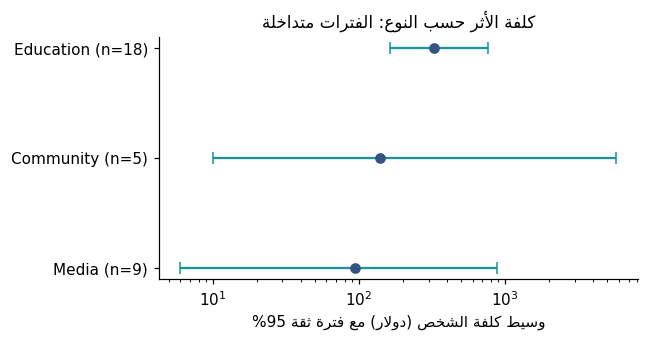

In [7]:
rng = np.random.default_rng(SEED)
cnt = A["type"].value_counts()
TYPES = list(cnt[cnt >= 5].index)
rows = []
for t in TYPES:
    v = A.loc[A["type"] == t, "cost_per_person"].values
    bs = [np.median(rng.choice(v, len(v))) for _ in range(5000)]
    rows.append((t, len(v), np.median(v), *np.percentile(bs, [2.5, 97.5])))
tt = pd.DataFrame(rows, columns=["type", "n", "median", "ci_low", "ci_high"]).sort_values("median")
display(tt.round(1))
kw_t = stats.kruskal(*[A.loc[A["type"] == t, "cost_per_person"] for t in TYPES])
print(f"Kruskal-Wallis بين الأنواع: p={kw_t.pvalue:.3f}  (الأنواع: {', '.join(TYPES)})")

fig, ax = plt.subplots(figsize=(6, 3.2))
y = np.arange(len(tt))
ax.errorbar(tt["median"], y, xerr=[tt["median"] - tt["ci_low"], tt["ci_high"] - tt["median"]], fmt="o", color=NAVY, ecolor=TEAL, capsize=4)
ax.set_yticks(y); ax.set_yticklabels([f"{t} (n={n})" for t, n in zip(tt["type"], tt["n"])])
ax.set_xscale("log"); ax.set_xlabel(ar("وسيط كلفة الشخص (دولار) مع فترة ثقة 95%"))
ax.set_title(ar("كلفة الأثر حسب النوع: الفترات متداخلة"), fontsize=11)
fig.tight_layout(); fig.savefig("outputs/figures/fig3_cost_by_type.png", dpi=160); plt.show()

## 7) التحقق من النتائج

In [8]:
# (1) إعادة حساب الوسيط بطريقة بديلة (بايثون الخالصة بدل pandas)
import statistics
for s in SIZES:
    sub = A[A["size"] == s]
    alt = statistics.median(f / p for f, p in zip(sub["Three-Year-Funding"], sub["Est. People Impacted"]))
    assert abs(alt - tab.loc[s, "median_cost_per_person"]) < 0.06, s
print("✔ الوسيط مطابق للحساب البديل لكل الأحجام")

# (2) حساسية: حذف أعلى 3 وأدنى 3 قيم كلفة، ما الذي يصمد؟
trim = A.sort_values("cost_per_person").iloc[3:-3]
m_trim = trim.groupby("size", observed=True)["cost_per_person"].median().reindex(SIZES)
mw_trim = stats.mannwhitneyu(trim.loc[trim["size"] == "كبير", "cost_per_person"], trim.loc[trim["size"] != "كبير", "cost_per_person"], alternative="greater")
large_robust = bool(m_trim["كبير"] > max(m_trim["صغير"], m_trim["متوسط"])) and mw_trim.pvalue < 0.05
small_med_stable = bool(m_trim["صغير"] < m_trim["متوسط"])
print("الوسيط بعد حذف الأطراف:", m_trim.round(1).to_dict())
print(f"الكبيرة تبقى الأغلى بفارق دال؟ {large_robust} (p={mw_trim.pvalue:.4f})")
print("الترتيب بين الصغيرة والمتوسطة مستقر؟", small_med_stable)

# (3) عدد الصفوف يتسق مع سجل الاستبعاد
assert N_A == attrition["المنظمات المتبقية"].iloc[-1]
print("✔ حجم العيّنة", N_A, "يطابق جدول الاستبعاد")

✔ الوسيط مطابق للحساب البديل لكل الأحجام
الوسيط بعد حذف الأطراف: {'صغير': 93.7, 'متوسط': 80.2, 'كبير': 430.7}
الكبيرة تبقى الأغلى بفارق دال؟ True (p=0.0070)
الترتيب بين الصغيرة والمتوسطة مستقر؟ False
✔ حجم العيّنة 54 يطابق جدول الاستبعاد


## 8) التقرير التنفيذي (PDF عربي، يُنتَج آليًا من النتائج)

In [9]:
s_med, m_med, l_med = (tab.loc[s, "median_cost_per_person"] for s in SIZES)
findings = [
    f"المبادرات الكبيرة (الثلث الأعلى تمويلًا) أعلى كلفة للشخص المتأثر: الوسيط {l_med:,.0f} دولارًا مقابل {m_med:,.0f} للمتوسطة و{s_med:,.0f} للصغيرة (الكبيرة مقابل البقية: p={mw.pvalue:.3f}).",
    (f"الفرق للمبادرات الكبيرة يبقى قائمًا بعد حذف أعلى 3 وأدنى 3 قيم (p={mw_trim.pvalue:.3f})" if large_robust else "الفرق للمبادرات الكبيرة لا يصمد بعد حذف القيم الطرفية")
    + ("." if small_med_stable else "، أما الترتيب بين الصغيرة والمتوسطة فغير مستقر ولا نبني عليه استنتاجًا."),
    f"مرونة الأثر للتمويل ≈ {slope:.2f} (فترة ثقة 95%: {lo:.2f} إلى {hi:.2f})، أي أن مضاعفة التمويل لا تضاعف الأثر المقدّر.",
    f"بين الأنواع ({'، '.join(TYPES)}) لا فرق دال إحصائيًا في الكلفة (p={kw_t.pvalue:.2f})، فلا نوصي بالتوزيع حسب النوع.",
]
if large_robust and mw.pvalue < 0.05:
    recs = ["تجربة توجيه جزء من التمويل المقبل إلى عدد أكبر من المبادرات الصغيرة والمتوسطة بدل رفع المنح الكبيرة، وقياس نتائجها.",
            "ربط زيادة المنح الكبيرة أو تجديدها بمراجعة أثر موحّدة.",
            "توحيد طريقة قياس الأثر والإبلاغ عنه بين الجهات الممولة."]
    decision = "القرار المقترح: بدء تجربة تمويل تجريبية ومقارنة النتائج قبل أي إعادة توزيع واسعة."
else:
    recs = ["لا توجد أدلة كافية لإعادة توزيع التمويل حسب الحجم.", "توحيد طريقة قياس الأثر وجمع بيانات أكمل."]
    decision = "القرار المقترح: الإبقاء على التوزيع الحالي مع تحسين جودة البيانات."

best = None
big, small = A[A["size"] == "كبير"], A[A["size"] == "صغير"]
for _, b in big.iterrows():
    for _, sm in small[(small["Est. People Impacted"] / b["Est. People Impacted"]).between(0.7, 1.4)].iterrows():
        r = b["Three-Year-Funding"] / sm["Three-Year-Funding"]
        if best is None or r > best[0]: best = (r, sm, b)
story = None
if best:
    r, sm, b = best
    short = lambda t: t if len(t) <= 34 else t[:32] + "…"
    story = (f"مثال توضيحي: {short(sm['label'])} (تمويل {sm['Three-Year-Funding']:,.0f} دولار) وصلت إلى نحو {sm['Est. People Impacted']:,.0f} شخص، "
             f"بينما {short(b['label'])} (تمويل {b['Three-Year-Funding']:,.0f} دولار) وصلت إلى نحو {b['Est. People Impacted']:,.0f}: أي {r:,.0f} ضعف التمويل لأثر مقارب (الأثر تقديري).")
    print(story)
limits = (f"حدود التحليل: {N_A} من {N_ALL} منظمة فقط صالحة (الباقي ناقص أو مشبوه)؛ الأثر تقديري وغير موحّد؛ "
          "العلاقة ارتباط لا سببية؛ البيانات دولية (غالبًا أمريكية)؛ لم تُؤكَّد رخصة البيانات بعد.")

def block(ax, x, y, title, items, size=10.5, width=62, bullet="• ", color="black"):
    ax.text(x, y, ar(title), ha="right", fontsize=size + 2, fontweight="bold", color=NAVY); y -= 0.035
    for it in items:
        for j, line in enumerate(textwrap.wrap(it, width)):
            ax.text(x, y, ar((bullet if j == 0 else "  ") + line), ha="right", fontsize=size, color=color); y -= 0.025
        y -= 0.010
    return y

with PdfPages("report/executive_summary.pdf") as pdf:
    fig, ax = plt.subplots(figsize=(8.27, 11.69)); ax.axis("off")
    ax.text(0.95, 0.95, ar("ملخص تنفيذي: كفاءة الأثر في مبادرات القطاع الثالث"), ha="right", fontsize=17, fontweight="bold", color=NAVY)
    ax.text(0.95, 0.92, ar(f"بوصلة الأثر · تحليل {N_A} منظمة من {N_ALL} · المصدر: Interdependence NGOs (Kaggle)"), ha="right", fontsize=10, color="gray")
    y = block(ax, 0.95, 0.87, "سؤال القرار", ["هل يرتفع الأثر بنفس نسبة ارتفاع التمويل، وأين تكون كلفة الأثر الأقل؟"])
    y = block(ax, 0.95, y - 0.01, "أهم النتائج", findings)
    y = block(ax, 0.95, y - 0.01, "التوصيات", recs)
    if story:
        y = block(ax, 0.95, y - 0.01, "مثال يوضح الفكرة", [story], bullet="")
    ax.text(0.95, y - 0.02, ar(decision), ha="right", fontsize=12, fontweight="bold", color=CORAL)
    for j, line in enumerate(textwrap.wrap(limits, 72)):
        ax.text(0.95, 0.06 - j * 0.022, ar(line), ha="right", fontsize=8.5, color="gray")
    pdf.savefig(fig); plt.close(fig)

    fig = plt.figure(figsize=(8.27, 11.69)); fig.text(0.95, 0.95, ar("الرسوم الداعمة"), ha="right", fontsize=17, fontweight="bold", color=NAVY)
    for p, yb in [("fig1_cost_by_size.png", 0.68), ("fig2_funding_vs_impact.png", 0.37), ("fig3_cost_by_type.png", 0.07)]:
        a = fig.add_axes([0.15, yb, 0.7, 0.27]); a.imshow(plt.imread(f"outputs/figures/{p}")); a.axis("off")
    pdf.savefig(fig); plt.close(fig)
print("✔ report/executive_summary.pdf")
print(*findings, sep="\n")

مثال توضيحي: Cultivate the Karass (تمويل 100,000 دولار) وصلت إلى نحو 10,000 شخص، بينما YWCA Metropolitan Chicago Racial… (تمويل 34,982,313 دولار) وصلت إلى نحو 10,000: أي 350 ضعف التمويل لأثر مقارب (الأثر تقديري).


✔ report/executive_summary.pdf
المبادرات الكبيرة (الثلث الأعلى تمويلًا) أعلى كلفة للشخص المتأثر: الوسيط 514 دولارًا مقابل 186 للمتوسطة و34 للصغيرة (الكبيرة مقابل البقية: p=0.005).
الفرق للمبادرات الكبيرة يبقى قائمًا بعد حذف أعلى 3 وأدنى 3 قيم (p=0.007)، أما الترتيب بين الصغيرة والمتوسطة فغير مستقر ولا نبني عليه استنتاجًا.
مرونة الأثر للتمويل ≈ 0.30 (فترة ثقة 95%: -0.05 إلى 0.66)، أي أن مضاعفة التمويل لا تضاعف الأثر المقدّر.
بين الأنواع (Education، Media، Community) لا فرق دال إحصائيًا في الكلفة (p=0.35)، فلا نوصي بالتوزيع حسب النوع.


## 9) استخدام الذكاء الاصطناعي والحدود
- استُخدم Claude (Anthropic) في التخطيط وصياغة الكود ومراجعته؛ التفاصيل والتحقق في `ai_usage_log.md`.
- لم تُدخل أي بيانات حساسة: البيانات عامة وعلى مستوى المنظمات.
- **الحدود:** عيّنة صغيرة (انظر جدول الاستبعاد)، والأثر تقدير غير موحّد، والعلاقات ارتباط لا سببية، والبيانات دولية في الغالب.